# Klasifikasi Performa Penjualan Produk Fashion untuk Mendukung Pengambilan Keputusan Bisnis Retail menggunakan Algoritma Random Forest

# 1. Business Understanding

## 1.1 Latar Belakang dan Permasalahan

Industri retail fashion memiliki berbagai jenis produk dengan karakteristik yang berbeda, seperti kategori produk, merek, ukuran, warna, musim, harga jual, diskon, dan jumlah produk yang terjual. Perbedaan karakteristik tersebut dapat memengaruhi performa penjualan setiap produk.

Dalam menjalankan bisnis retail, perusahaan perlu memahami produk yang memiliki performa penjualan tinggi, sedang, maupun rendah. Informasi tersebut dapat membantu perusahaan dalam menentukan strategi bisnis, seperti pengelolaan persediaan, penentuan strategi promosi, dan evaluasi produk.

Namun, banyaknya karakteristik produk dan transaksi membuat analisis performa penjualan tidak cukup dilakukan hanya dengan mengamati satu atau dua variabel. Oleh karena itu, diperlukan pendekatan machine learning yang mampu mempelajari hubungan antara berbagai karakteristik produk dengan kategori performa penjualannya.

Pada proyek ini, dilakukan klasifikasi performa penjualan produk fashion menggunakan algoritma Random Forest. Model akan memanfaatkan karakteristik produk, harga, diskon, jumlah penjualan, serta informasi pendukung lainnya untuk mengklasifikasikan produk ke dalam kategori High Sales, Medium Sales, dan Low Sales.

Hasil klasifikasi diharapkan dapat memberikan informasi yang mendukung pengambilan keputusan bisnis retail, khususnya dalam memahami karakteristik produk berdasarkan performa penjualannya.

## 1.2 Rumusan Masalah

Berdasarkan permasalahan tersebut, rumusan masalah dalam proyek ini adalah:

1. Bagaimana karakteristik produk fashion yang terdapat dalam dataset dan bagaimana hubungannya dengan kategori performa penjualan?
2. Bagaimana menerapkan algoritma Random Forest untuk mengklasifikasikan performa penjualan produk fashion?
3. Seberapa baik algoritma Random Forest dalam mengklasifikasikan produk ke dalam kategori High Sales, Medium Sales, dan Low Sales?
4. Karakteristik atau fitur apa saja yang memiliki kontribusi penting dalam proses klasifikasi performa penjualan produk fashion?

## 1.3 Tujuan

Tujuan dari proyek ini adalah:

1. Memahami karakteristik dataset penjualan produk fashion melalui proses eksplorasi dan analisis data.
2. Membangun model klasifikasi performa penjualan produk fashion menggunakan algoritma Random Forest.
3. Mengevaluasi kemampuan model dalam mengklasifikasikan kategori performa penjualan.
4. Mengidentifikasi fitur yang memiliki kontribusi penting terhadap hasil klasifikasi sebagai informasi pendukung pengambilan keputusan bisnis retail.

## 1.4 Metode yang Digunakan

Metode yang digunakan dalam proyek ini adalah klasifikasi (*Classification*) dengan algoritma Random Forest.

Random Forest merupakan algoritma machine learning berbasis ensemble learning yang menggabungkan sejumlah decision tree untuk menghasilkan prediksi. Dalam proyek ini, Random Forest digunakan untuk mempelajari pola dari karakteristik produk fashion dan mengklasifikasikan performa penjualannya ke dalam tiga kategori, yaitu:

- High Sales
- Medium Sales
- Low Sales

Tahapan pengerjaan proyek mengikuti alur CRISP-DM, yaitu Business Understanding, Data Understanding, Data Preparation, Modeling, Evaluation, dan Conclusion.

## 1.5 Metrik Evaluasi

Evaluasi model dilakukan menggunakan beberapa metrik untuk mengetahui kemampuan model dalam mengklasifikasikan setiap kategori performa penjualan.

Metrik yang digunakan meliputi:

1. **Accuracy:** Mengukur persentase keseluruhan prediksi yang benar dibandingkan dengan seluruh data pengujian.
2. **Precision:** Mengukur ketepatan prediksi model pada setiap kategori penjualan.
3. **Recall:** Mengukur kemampuan model dalam menemukan seluruh data aktual pada setiap kategori penjualan.
4. **F1-Score:** Mengukur keseimbangan antara precision dan recall.
5. **Confusion Matrix:** Menampilkan perbandingan antara kategori aktual dan hasil prediksi model untuk mengetahui jenis kesalahan klasifikasi.

Macro F1-Score digunakan sebagai metrik utama karena memberikan bobot yang sama kepada setiap kelas, sehingga evaluasi tidak hanya didominasi oleh kategori dengan jumlah data terbanyak. Accuracy, precision, recall, dan confusion matrix digunakan sebagai metrik pendukung.

Pemilihan metrik ini akan membantu mengetahui apakah model mampu mengklasifikasikan ketiga kategori performa penjualan secara seimbang.

# 2. Data Gathering

In [1]:
#import library
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,f1_score)

In [2]:
df = pd.read_csv("Multiclass_Clothing_Sales_Dataset.csv")
display(df.head())
print("Jumlah Baris:", df.shape[0])
print("Jumlah Kolom:", df.shape[1])

print("\nInformasi Dataset:")
df.info()

,Product_Category,Brand,Product_Name,Gender,Size,Color,Season,Payment_Method,Customer_Type,Selling_Price,Cost_Price,Discount_Percentage,Quantity_Sold,Total_Sales,Stock_Availability,Customer_Age,Purchase_Frequency,Store_Rating,Return_Rate,Sales_Category
0,Traditional Wear,Forever 21,Tops,Women,S,White,Winter,Card,New,1817.433878,816.027585,26.260791,6,42241.692855,294.0,58.0,2.560957,3.106155,29.293331,High Sales
1,Athleisure,Ralph Lauren,Casual Shirt,Men,XXL,Yellow,All-Season,Card,Returning,1672.038198,793.236861,26.882613,8,69318.541482,376.0,40.0,1.590993,3.428439,19.473670,Low Sales
2,Outerwear,Nike,Blazer,Men,S,Green,All-Season,UPI,Returning,1381.568069,890.469629,30.274720,5,56851.121070,48.0,41.0,3.066213,3.765591,22.083407,Medium Sales
3,Athleisure,Zara,Leggings,Women,M,White,Winter,UPI,Returning,859.507388,1497.080062,NaN,4,72084.361720,362.0,32.0,2.194826,4.530297,17.282082,Medium Sales
4,Athleisure,Zara,Dress,Men,XL,Yellow,Summer,Net Banking,Returning,1642.176945,896.187442,NaN,2,29846.082696,34.0,27.0,2.014097,4.644271,9.379608,Medium Sales


Jumlah Baris: 100000
Jumlah Kolom: 20

Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   Product_Category     100000 non-null  str    
 1   Brand                100000 non-null  str    
 2   Product_Name         100000 non-null  str    
 3   Gender               100000 non-null  str    
 4   Size                 100000 non-null  str    
 5   Color                100000 non-null  str    
 6   Season               100000 non-null  str    
 7   Payment_Method       100000 non-null  str    
 8   Customer_Type        100000 non-null  str    
 9   Selling_Price        95000 non-null   float64
 10  Cost_Price           100000 non-null  float64
 11  Discount_Percentage  95000 non-null   float64
 12  Quantity_Sold        100000 non-null  int64  
 13  Total_Sales          100000 non-null  float64
 14  Stock_Availability   9

## 2.1 Sumber Datsaet dan Tautan Dataset
**Sumber**  : Kaggle "Dynamic Apparel Sales Dataset with Anomalies"
**Tautan**  : https://www.kaggle.com/datasets/rayzem/dynamic-apparel-sales-dataset-with-anomalies

## 2.2 Deskripsi Dataset

Dataset yang digunakan dalam proyek ini merupakan dataset penjualan produk fashion pada bisnis retail. Dataset berisi informasi mengenai karakteristik produk, merek, kategori produk, preferensi pelanggan, metode pembayaran, harga, diskon, jumlah produk terjual, ketersediaan stok, serta informasi performa penjualan.

Dataset memiliki total 100.000 baris data dan 20 kolom. Setiap baris merepresentasikan satu catatan data penjualan produk fashion beserta karakteristik yang menyertainya.

Data mencakup beberapa aspek, yaitu:
1. **Informasi Produk:** Kategori produk, merek, nama produk, gender, ukuran, warna, dan musim.
2. **Informasi Pelanggan dan Transaksi:** Metode pembayaran, tipe pelanggan, usia pelanggan, dan frekuensi pembelian.
3. **Informasi Penjualan:** Harga jual, harga modal, persentase diskon, jumlah produk terjual, dan total penjualan.
4. **Informasi Persediaan dan Kinerja:** Ketersediaan stok, rating toko, tingkat pengembalian produk, dan kategori performa penjualan.

Kolom `Sales_Category` digunakan sebagai variabel target yang akan diprediksi menggunakan algoritma Random Forest. Variabel tersebut memiliki tiga kategori, yaitu High Sales, Medium Sales, dan Low Sales.

## 2.3 Alasan Pemilihan Dataset

Dataset penjualan produk fashion dipilih karena memiliki karakteristik yang sesuai dengan tujuan proyek klasifikasi performa penjualan produk retail.

Beberapa alasan pemilihan dataset ini adalah:

1. **Relevan dengan permasalahan bisnis:** Data penjualan produk fashion dapat digunakan untuk mempelajari karakteristik produk berdasarkan performa penjualannya.
2. **Jumlah data memadai:** Dataset memiliki 100.000 baris sehingga menyediakan jumlah observasi yang cukup besar untuk proses eksplorasi, preprocessing, pemodelan, dan evaluasi.
3. **Memiliki beragam karakteristik:** Dataset mengandung fitur kategorikal dan numerik yang memungkinkan analisis hubungan antara karakteristik produk, pelanggan, transaksi, dan performa penjualan.
4. **Memiliki variabel target:** Kolom `Sales_Category` menyediakan kategori performa penjualan yang dapat digunakan dalam permasalahan klasifikasi multiclass.
5. **Mendukung pengambilan keputusan bisnis:** Hasil klasifikasi dan analisis fitur dapat memberikan informasi pendukung dalam memahami performa produk dan menentukan strategi bisnis retail.

## 2.4 Struktur dan Pengertian Setiap Kolom

Dataset memiliki 20 kolom dengan penjelasan sebagai berikut:

| No. | Nama Kolom | Pengertian |
|---|---|---|
| 1 | Product_Category | Kategori produk fashion, seperti Traditional Wear. |
| 2 | Brand | Merek atau produsen produk fashion. |
| 3 | Product_Name | Nama atau jenis produk yang tercatat dalam dataset. |
| 4 | Gender | Segmentasi gender yang menjadi sasaran produk. |
| 5 | Size | Ukuran produk fashion. |
| 6 | Color | Warna produk. |
| 7 | Season | Musim atau periode penggunaan produk. |
| 8 | Payment_Method | Metode pembayaran yang digunakan pelanggan. |
| 9 | Customer_Type | Jenis atau segmen pelanggan. |
| 10 | Selling_Price | Harga jual produk. |
| 11 | Cost_Price | Harga modal atau biaya perolehan produk. |
| 12 | Discount_Percentage | Persentase diskon yang diberikan pada produk. |
| 13 | Quantity_Sold | Jumlah produk yang terjual. |
| 14 | Total_Sales | Total nilai penjualan yang tercatat. |
| 15 | Stock_Availability | Jumlah atau ketersediaan stok produk. |
| 16 | Customer_Age | Usia pelanggan. |
| 17 | Purchase_Frequency | Frekuensi pembelian pelanggan. |
| 18 | Store_Rating | Nilai rating atau penilaian toko. |
| 19 | Return_Rate | Tingkat pengembalian produk. |
| 20 | Sales_Category | Kategori performa penjualan produk, yaitu High Sales, Medium Sales, dan Low Sales. |



# 3. EDA Exploratory Data Analysis

## 3.1 Gambaran Umum Dataset
Tujuan: mengetahui ukuran dataset, tipe data, dan gambaran awal karakteristik data.

In [3]:
print("Jumlah Baris:", df.shape[0])
print("Jumlah Kolom:", df.shape[1])

display(df.head())

print("\nInformasi Dataset:")
df.info()

Jumlah Baris: 100000
Jumlah Kolom: 20


,Product_Category,Brand,Product_Name,Gender,Size,Color,Season,Payment_Method,Customer_Type,Selling_Price,Cost_Price,Discount_Percentage,Quantity_Sold,Total_Sales,Stock_Availability,Customer_Age,Purchase_Frequency,Store_Rating,Return_Rate,Sales_Category
0,Traditional Wear,Forever 21,Tops,Women,S,White,Winter,Card,New,1817.433878,816.027585,26.260791,6,42241.692855,294.0,58.0,2.560957,3.106155,29.293331,High Sales
1,Athleisure,Ralph Lauren,Casual Shirt,Men,XXL,Yellow,All-Season,Card,Returning,1672.038198,793.236861,26.882613,8,69318.541482,376.0,40.0,1.590993,3.428439,19.473670,Low Sales
2,Outerwear,Nike,Blazer,Men,S,Green,All-Season,UPI,Returning,1381.568069,890.469629,30.274720,5,56851.121070,48.0,41.0,3.066213,3.765591,22.083407,Medium Sales
3,Athleisure,Zara,Leggings,Women,M,White,Winter,UPI,Returning,859.507388,1497.080062,NaN,4,72084.361720,362.0,32.0,2.194826,4.530297,17.282082,Medium Sales
4,Athleisure,Zara,Dress,Men,XL,Yellow,Summer,Net Banking,Returning,1642.176945,896.187442,NaN,2,29846.082696,34.0,27.0,2.014097,4.644271,9.379608,Medium Sales



Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   Product_Category     100000 non-null  str    
 1   Brand                100000 non-null  str    
 2   Product_Name         100000 non-null  str    
 3   Gender               100000 non-null  str    
 4   Size                 100000 non-null  str    
 5   Color                100000 non-null  str    
 6   Season               100000 non-null  str    
 7   Payment_Method       100000 non-null  str    
 8   Customer_Type        100000 non-null  str    
 9   Selling_Price        95000 non-null   float64
 10  Cost_Price           100000 non-null  float64
 11  Discount_Percentage  95000 non-null   float64
 12  Quantity_Sold        100000 non-null  int64  
 13  Total_Sales          100000 non-null  float64
 14  Stock_Availability   95000 non-null   float64
 15  Customer_

## 3.2 Statistik Deskriptif

In [4]:
# Statistik Deskriptif Fitur Numerik

display(df.describe().T)

# Statistik Deskriptif Fitur Kategorikal

display(df.describe(include="object").T)

,count,mean,std,min,25%,50%,75%,max
Selling_Price,95000.0,1554.029505,974.709187,-613.615890,1162.144173,1501.409850,1842.752501,19989.216427
Cost_Price,100000.0,1041.472376,734.619046,-726.934992,732.336452,1005.567011,1276.944645,14992.757159
Discount_Percentage,95000.0,24.994389,14.431100,0.000127,12.447380,25.007454,37.450829,49.999563
Quantity_Sold,100000.0,5.348760,7.215449,1.000000,3.000000,5.000000,7.000000,199.000000
Total_Sales,100000.0,50051.437498,20076.412144,-37155.408729,36596.251916,50115.894604,63504.829774,141640.191523
Stock_Availability,95000.0,250.329842,144.472592,0.000000,126.000000,251.000000,376.000000,499.000000
Customer_Age,95000.0,41.066821,13.567101,18.000000,29.000000,41.000000,53.000000,64.000000
Purchase_Frequency,100000.0,2.081108,1.896919,-2.096379,1.327364,2.001746,2.685177,49.000000
Store_Rating,95000.0,3.995121,0.586217,1.002394,3.497587,3.995872,4.497780,4.999984
Return_Rate,100000.0,14.956974,8.651961,0.000492,7.435705,14.960901,22.440826,29.999077


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_2084\204589020.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object").T)


,count,unique,top,freq
Product_Category,100000,5,Athleisure,20187
Brand,100000,20,Wrangler,5134
Product_Name,100000,20,Dress,5090
Gender,100000,2,Men,50175
Size,100000,5,L,20064
Color,100000,9,White,11272
Season,100000,3,Winter,33488
Payment_Method,100000,4,Card,25144
Customer_Type,100000,2,New,50255
Sales_Category,100000,3,High Sales,33561


## 3.3 Analisis Distribusi Target

,Jumlah Data
Sales_Category,
High Sales,33561
Low Sales,33300
Medium Sales,33139


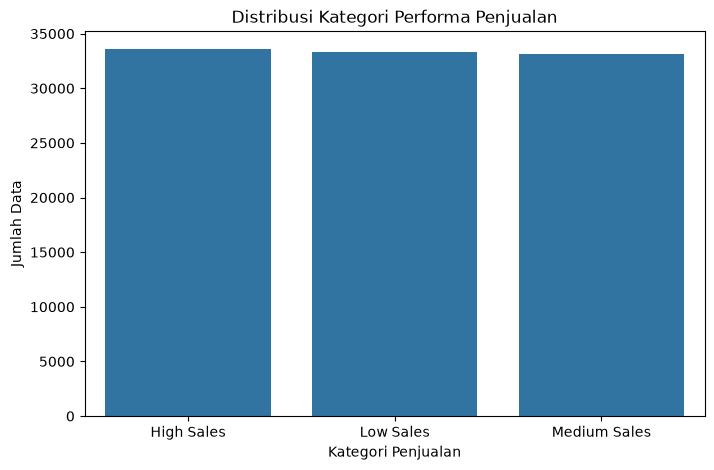

In [5]:

# Distribusi Target

target_counts = df["Sales_Category"].value_counts()

display(target_counts.to_frame("Jumlah Data"))

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Sales_Category",
              order=target_counts.index)

plt.title("Distribusi Kategori Performa Penjualan")
plt.xlabel("Kategori Penjualan")
plt.ylabel("Jumlah Data")
plt.show()


**Temuan 3.3 — Distribusi kategori penjualan.**

Jumlah data pada ketiga kelas hampir seimbang: High Sales 33.561, Low Sales 33.300, dan Medium Sales 33.139 dari total 100.000 baris. Proporsi masing-masing berkisar 33,1%–33,6%, dengan selisih maksimum hanya 422 data. Tidak ada ketimpangan kelas yang serius, sehingga tidak diperlukan penyeimbangan kelas; metrik macro F1 tetap dipakai sebagai metrik utama sesuai Bab 1 agar setiap kelas mendapat bobot yang sama.

## 3.4 Distribusi Fitur Numerik

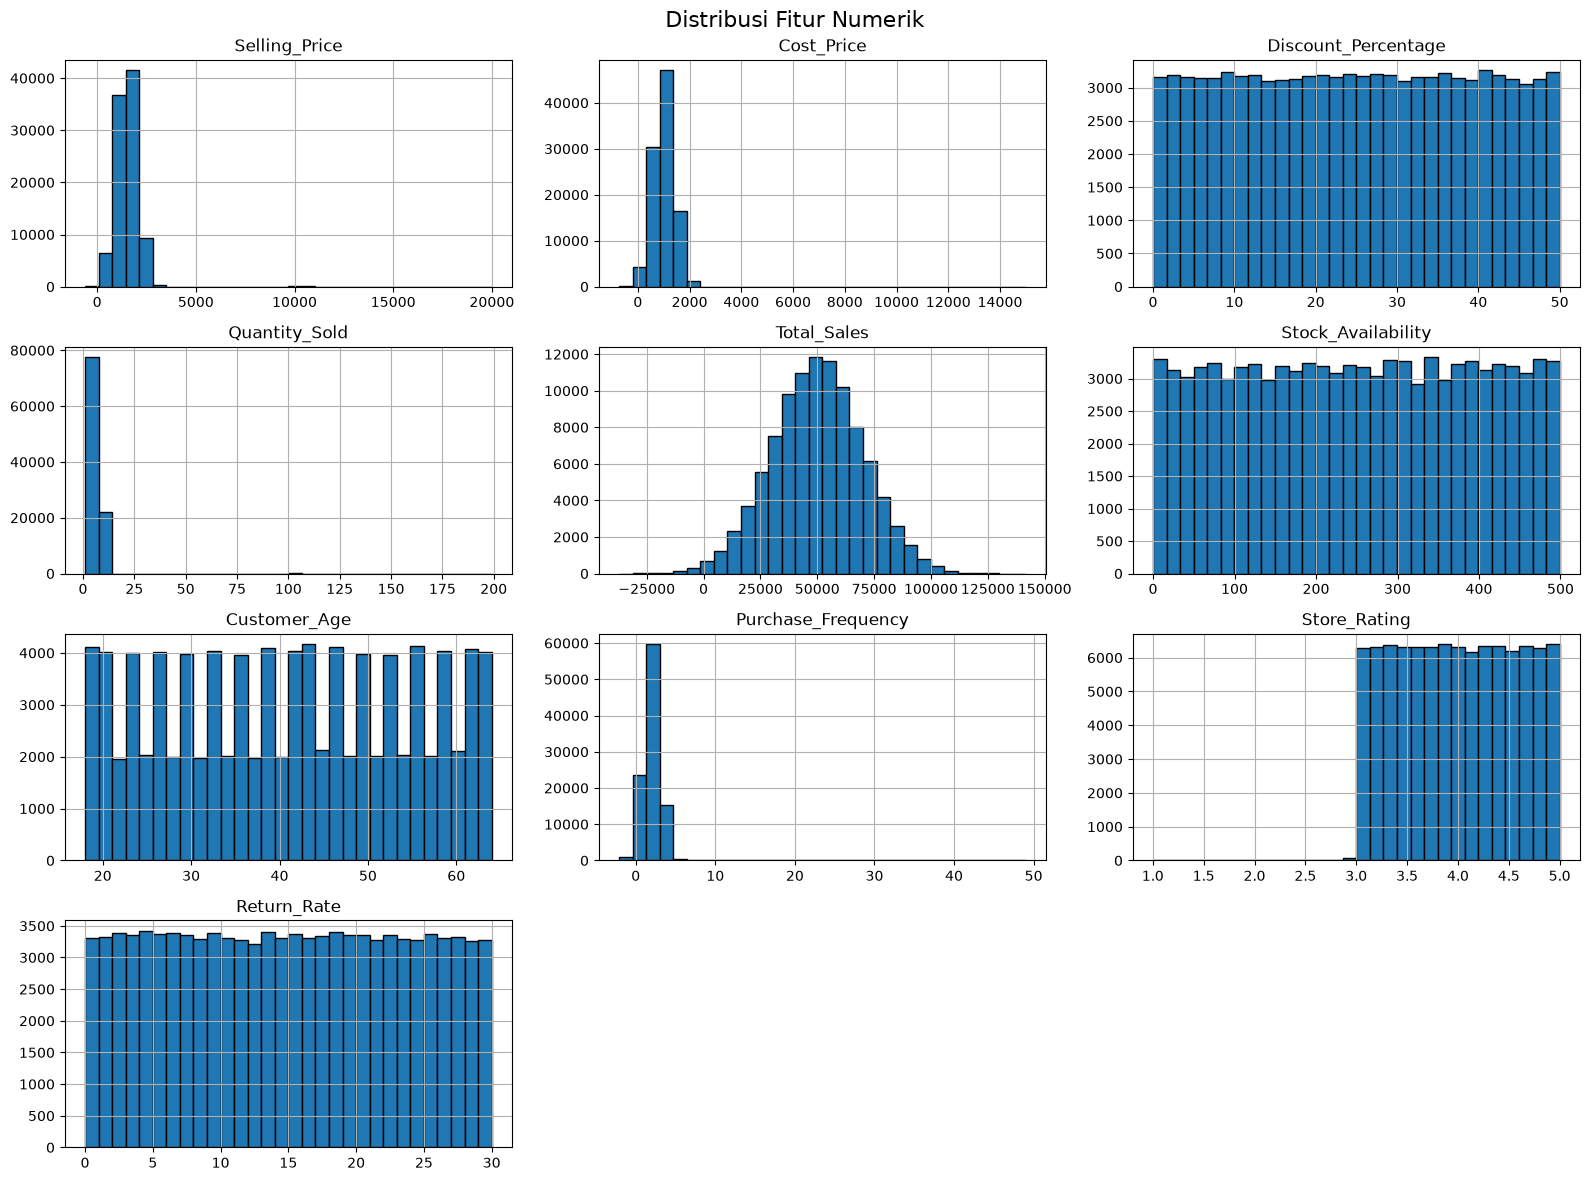

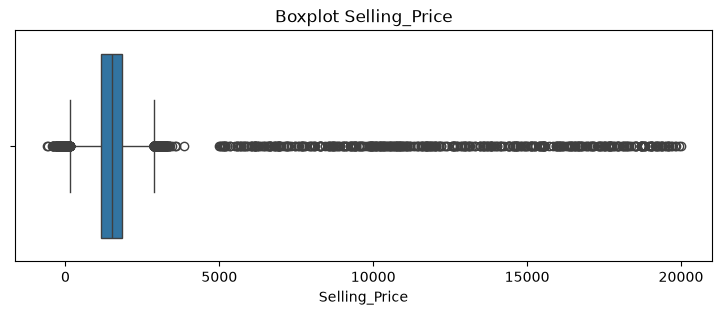

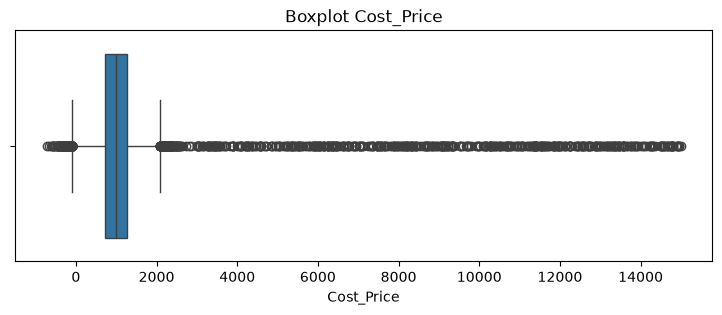

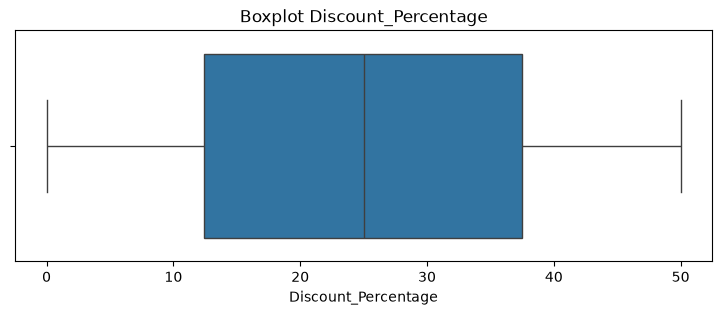

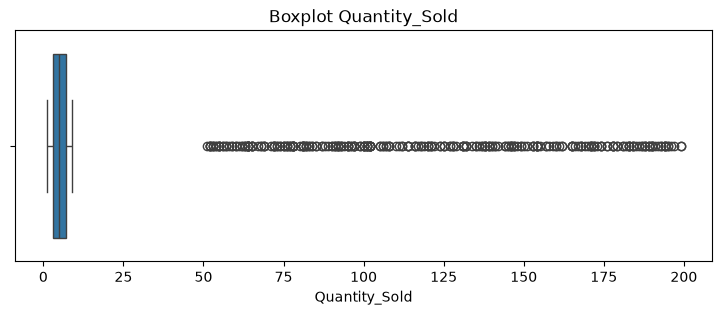

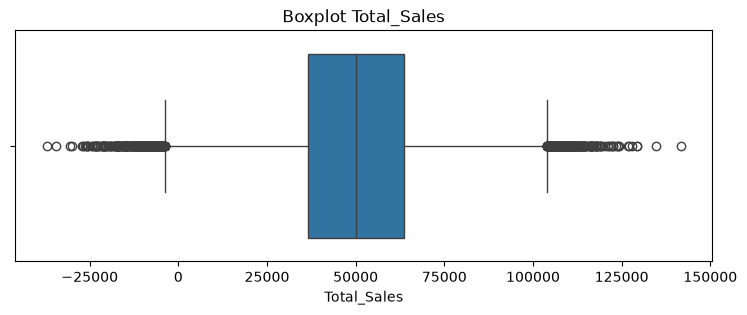

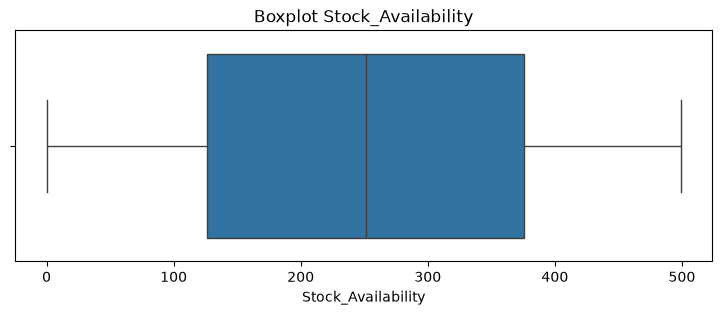

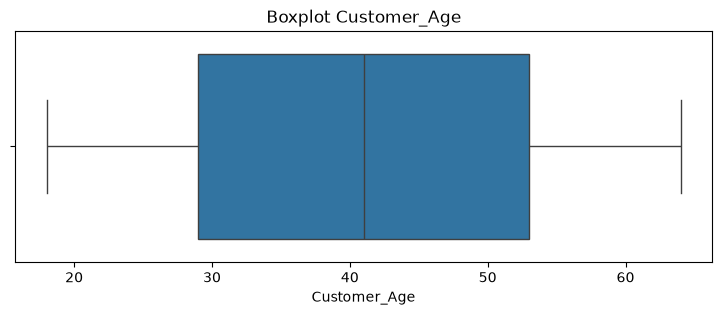

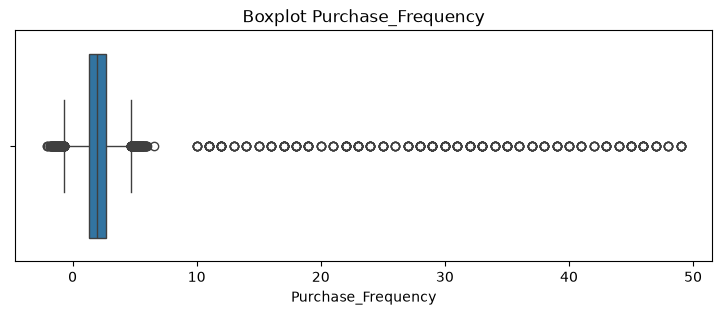

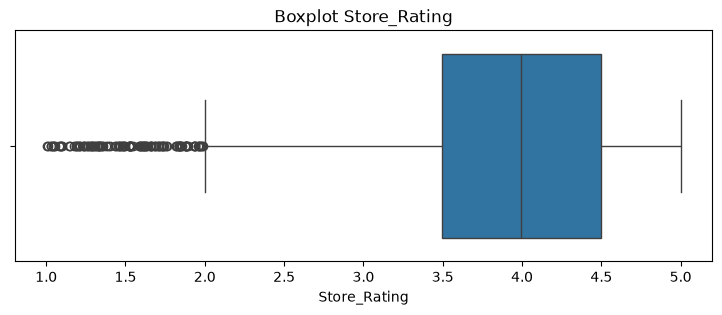

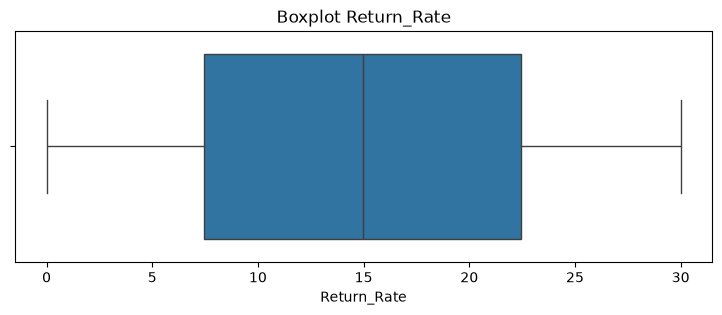

In [6]:

# Distribusi Fitur Numerik

numeric_cols = df.select_dtypes(include=np.number).columns

df[numeric_cols].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribusi Fitur Numerik", fontsize=16)
plt.tight_layout()
plt.show()


# Boxplot Fitur Numerik

for col in numeric_cols:
    plt.figure(figsize=(9, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot {col}")
    plt.xlabel(col)
    plt.show()


### Insight 3.4 — Distribusi Fitur Numerik

Histogram menunjukkan `Selling_Price` dan `Cost_Price` terkonsentrasi di kisaran ≈1.000–1.800 dengan ekor panjang hingga ≈19.989 dan ≈14.993; `Discount_Percentage` tersebar merata 0–50; `Quantity_Sold` sebagian besar 1–7 dengan ekor sampai 199; `Total_Sales` berpusat di ≈50.000; `Customer_Age` 18–64; `Purchase_Frequency` berpusat di ≈2 dengan ekor sampai 49; `Store_Rating` 1–5; `Return_Rate` 0–30.

Boxplot mengonfirmasi banyaknya outlier pada `Selling_Price`, `Cost_Price`, `Quantity_Sold`, `Total_Sales`, dan `Purchase_Frequency`. Beberapa nilai minimum juga negatif: `Selling_Price` ≈ −613,6; `Cost_Price` ≈ −726,9; `Total_Sales` ≈ −37.155; `Purchase_Frequency` ≈ −2,10 — tidak wajar untuk harga, total penjualan, maupun frekuensi. Sebaliknya `Discount_Percentage`, `Customer_Age`, `Store_Rating`, dan `Return_Rate` masih dalam rentang wajar. Temuan ini menjadi dasar pengecekan dan penanganan anomali di Bab 4.

## 3.5 Analisis Distribusi Fitur Kategorikal

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_2084\222156182.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(


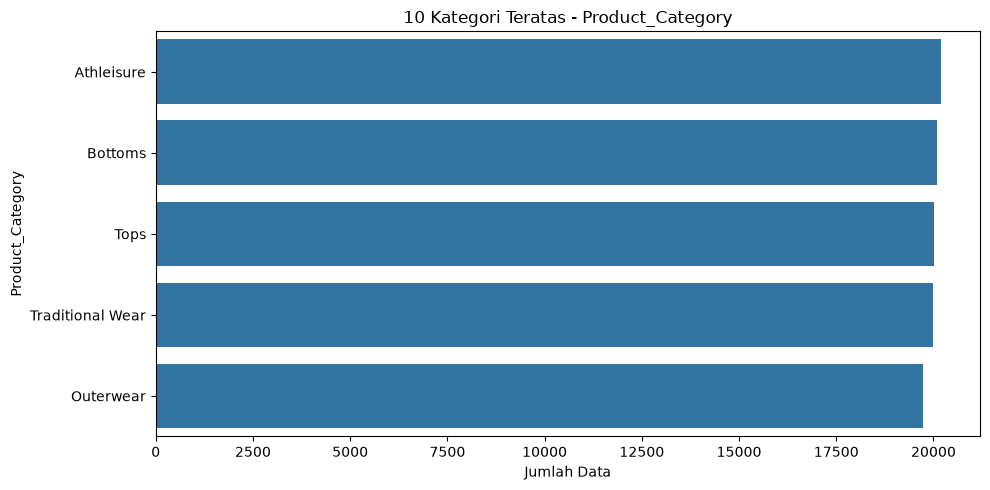

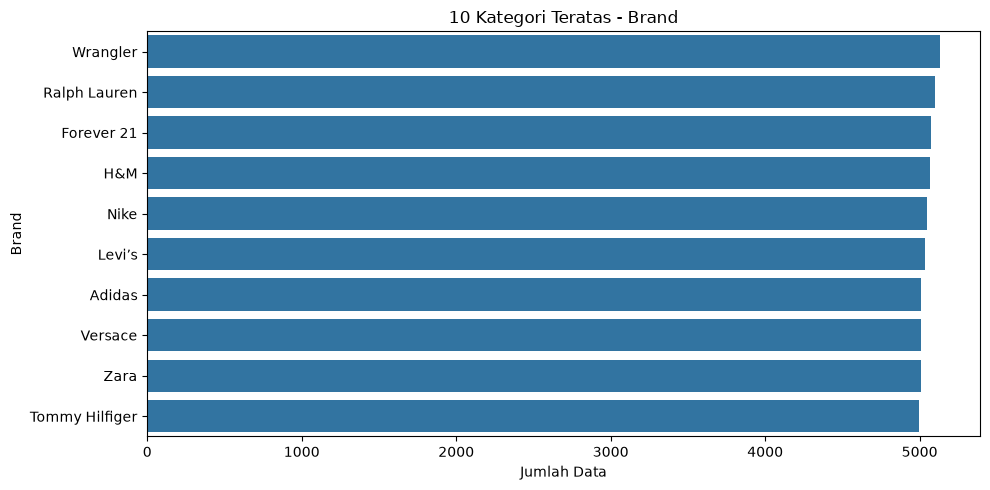

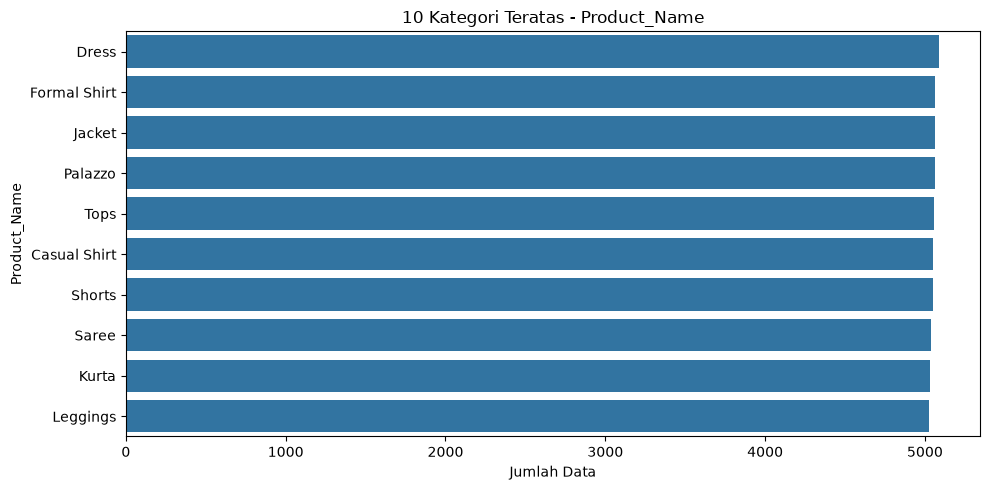

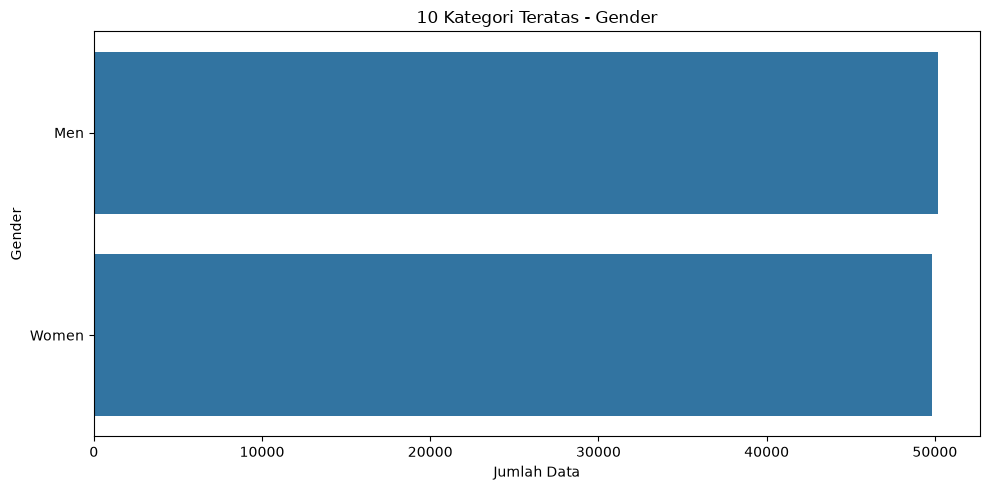

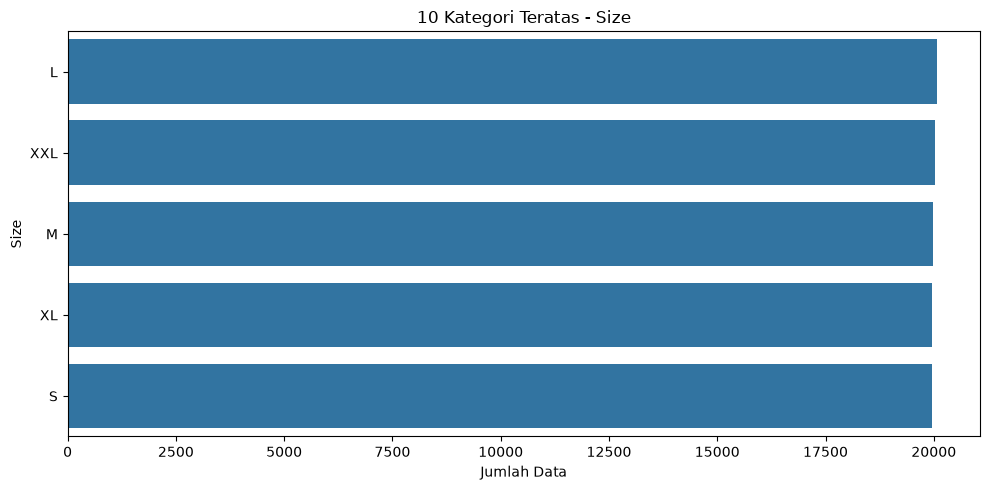

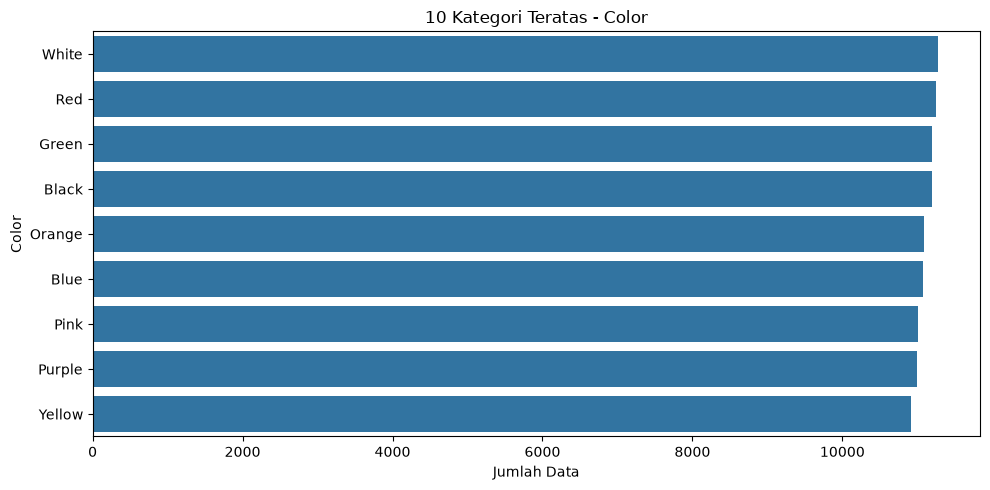

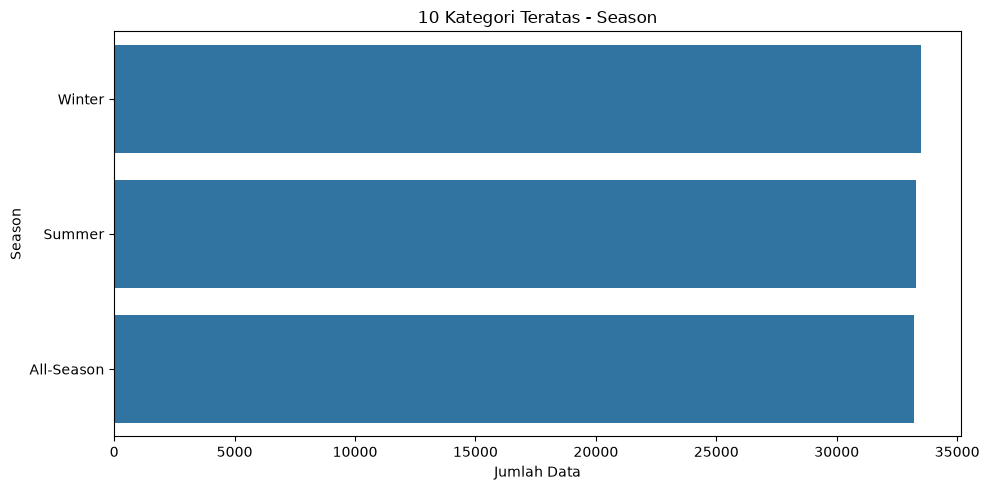

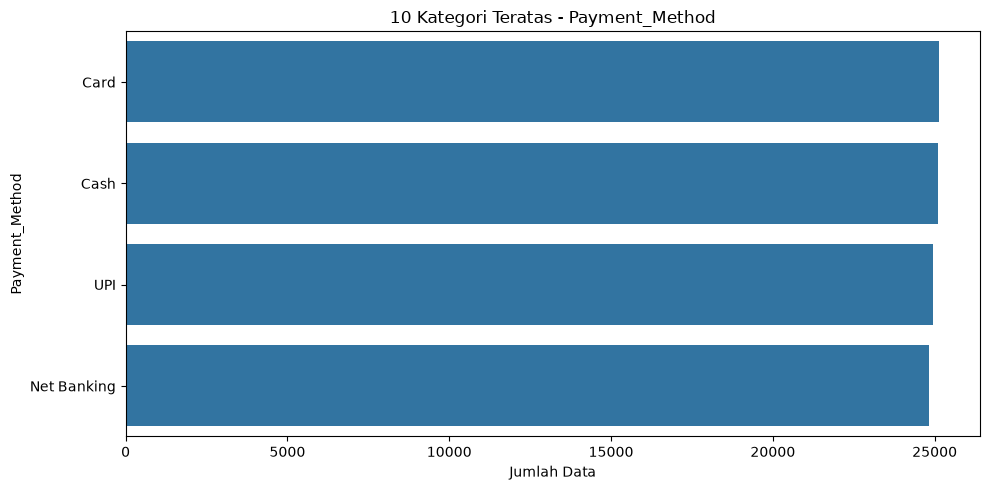

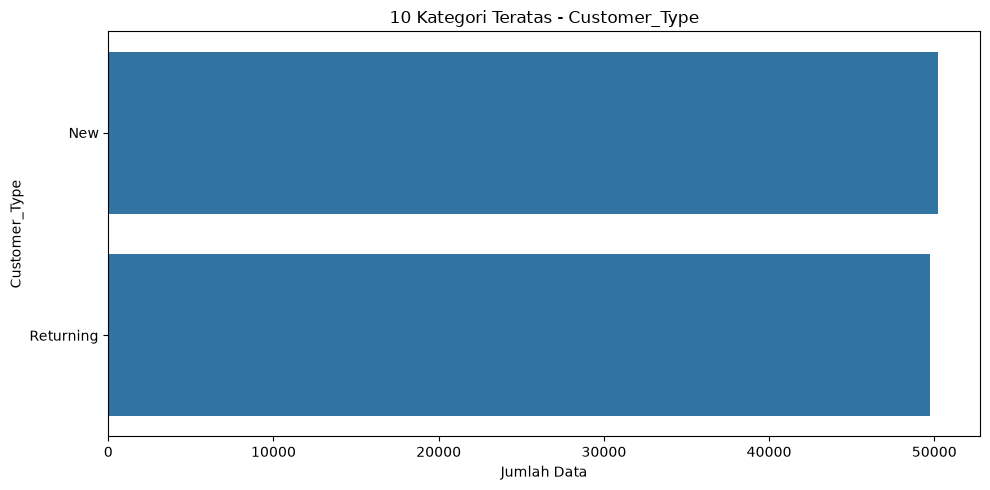

In [7]:

# Distribusi Fitur Kategorikal

categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns.drop("Sales_Category", errors="ignore")

for col in categorical_cols:
    top_values = df[col].value_counts().head(10)

    plt.figure(figsize=(10, 5))
    sns.barplot(
        x=top_values.values,
        y=top_values.index
    )

    plt.title(f"10 Kategori Teratas - {col}")
    plt.xlabel("Jumlah Data")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()


**Temuan 3.5 — Distribusi fitur kategorikal.**

`Product_Category` memiliki 5 kategori (terbanyak Athleisure 20.187), `Brand` 20 merek (terbanyak Wrangler 5.134), `Product_Name` 20 jenis (terbanyak Dress 5.090), `Gender` 2 (Men 50.175), `Size` 5 (L 20.064), `Color` 9 (White 11.272), `Season` 3 (Winter 33.488), `Payment_Method` 4 (Card 25.144), dan `Customer_Type` 2 (New 50.255). Sebaran antarkategori cenderung merata — tidak ada kategori yang mendominasi secara ekstrem (misalnya Gender hampir 50:50). Dengan demikian belum ada kategori yang perlu dibuang karena kemunculannya terlalu jarang.

## 3.6 Analisis Korelasi Antarfitur Numerik

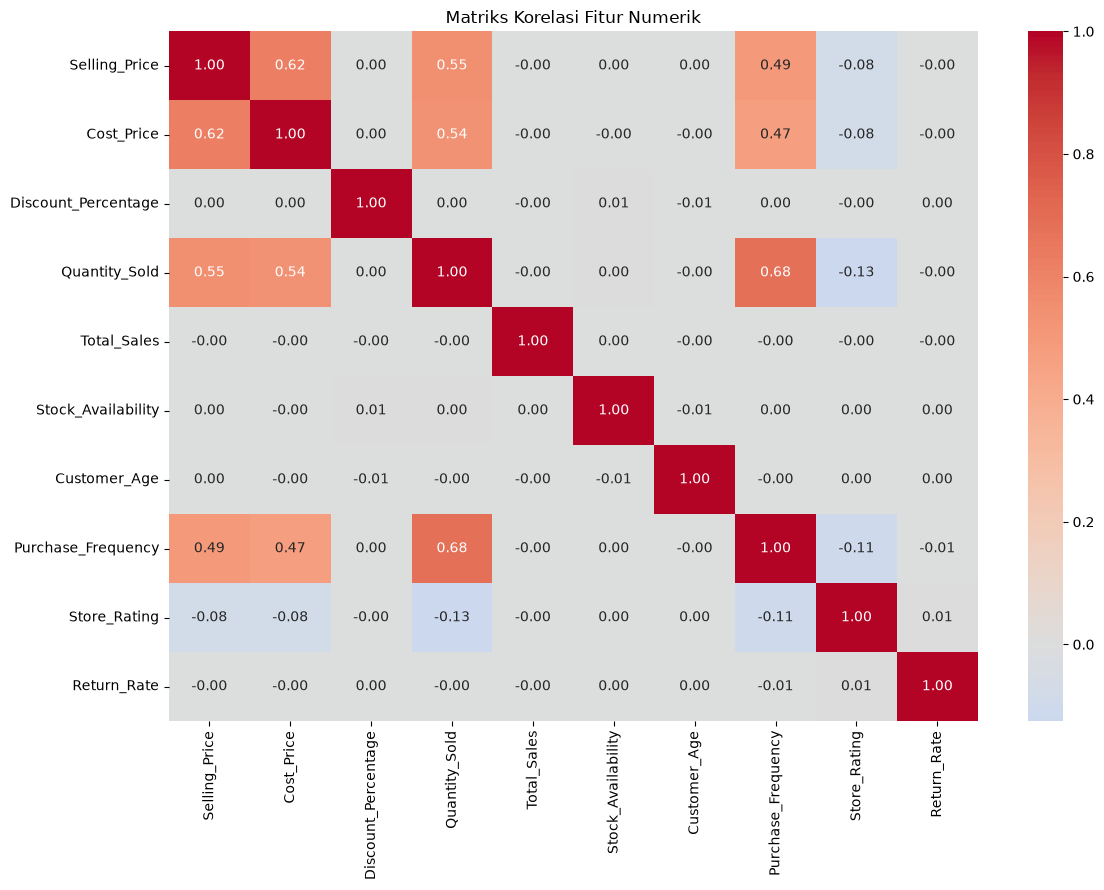

In [8]:

# Matriks Korelasi

correlation = df[numeric_cols].corr(method="pearson")

plt.figure(figsize=(12, 9))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Matriks Korelasi Fitur Numerik")
plt.tight_layout()
plt.show()


**Temuan 3.6 — Korelasi antarfitur numerik.**

Sebagian besar pasangan fitur numerik berkorelasi sangat lemah (|r| < 0,1), tetapi ada tiga pasangan yang berkorelasi sedang: `Purchase_Frequency`–`Quantity_Sold` (r ≈ 0,68), `Selling_Price`–`Cost_Price` (r ≈ 0,62), dan `Selling_Price`–`Quantity_Sold` (r ≈ 0,55). Korelasi terendah adalah `Store_Rating`–`Quantity_Sold` (r ≈ −0,13). Tidak ada pasangan dengan |r| > 0,8, sehingga pada tahap ini belum ada fitur yang dibuang hanya karena redundansi; hubungan ini akan dipertimbangkan lagi saat feature selection di Bab 4.

## 3.7 Analisis Hubungan Fitur dengan Target

### 3.7.1 Hubungan fitur numerik dengan kategori penjualan

Sales_Category,High Sales,Low Sales,Medium Sales
Selling_Price,1553.890093,1546.512494,1561.722420
Cost_Price,1038.935795,1039.810722,1045.710986
Discount_Percentage,24.944005,25.022370,25.017280
Quantity_Sold,5.389530,5.311982,5.344428
Total_Sales,50008.005216,50014.201813,50132.839443
Stock_Availability,249.714944,250.834323,250.445387
Customer_Age,41.108721,40.923019,41.168971
Purchase_Frequency,2.090572,2.074090,2.078576
Store_Rating,3.995800,3.992624,3.996942
Return_Rate,15.002623,14.959221,14.908485


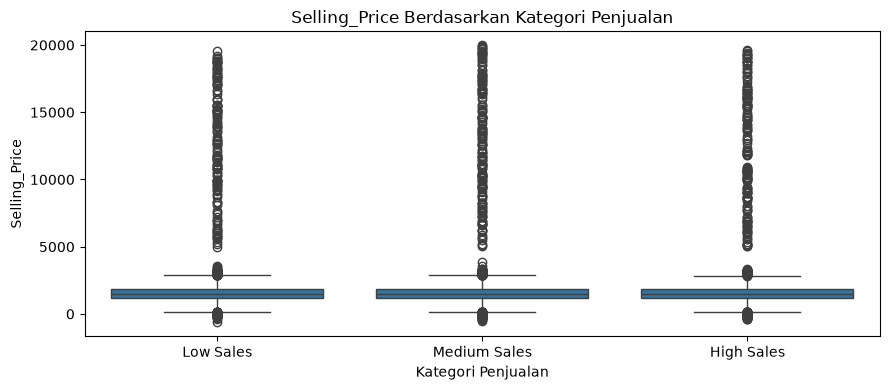

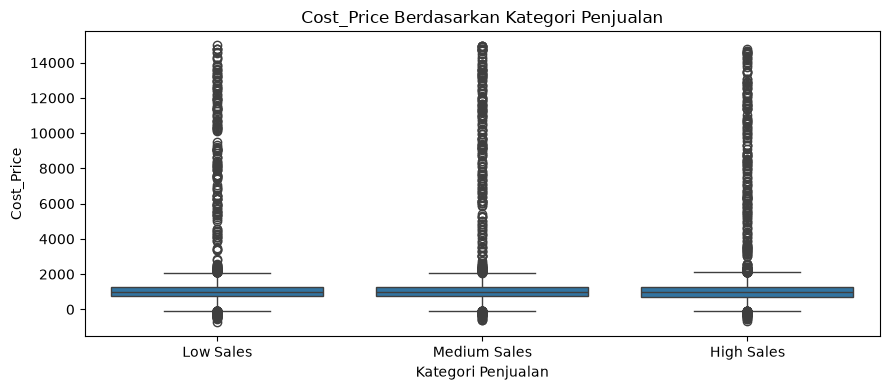

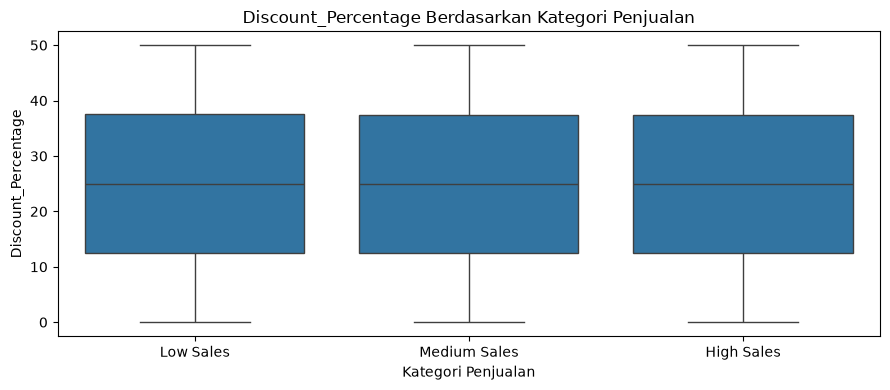

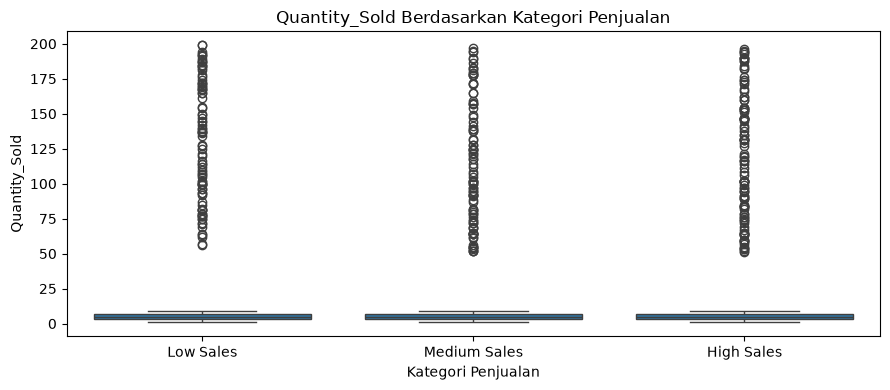

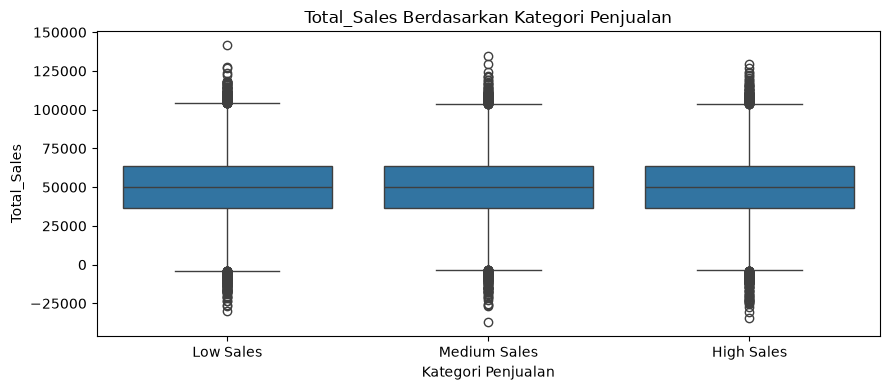

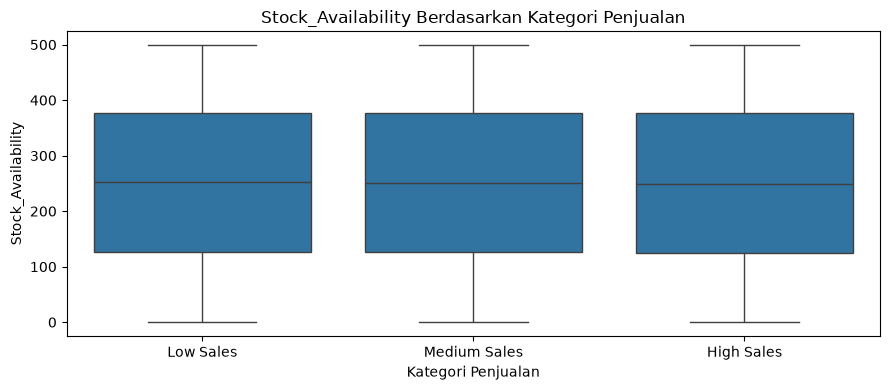

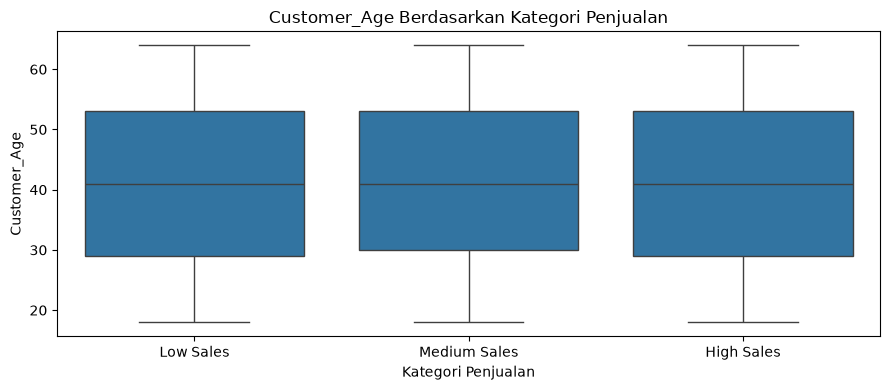

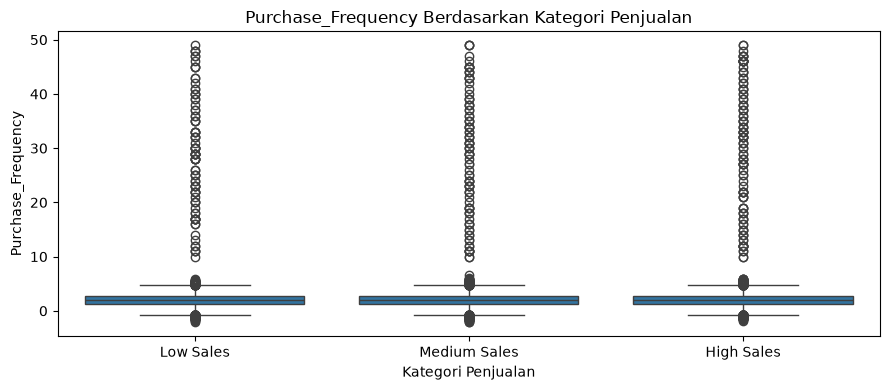

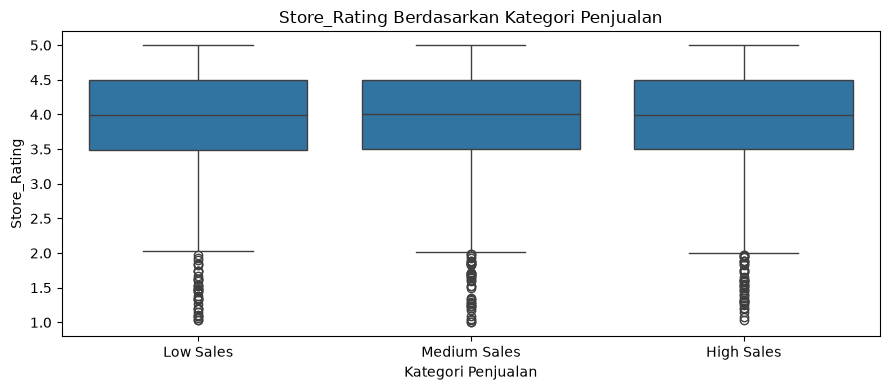

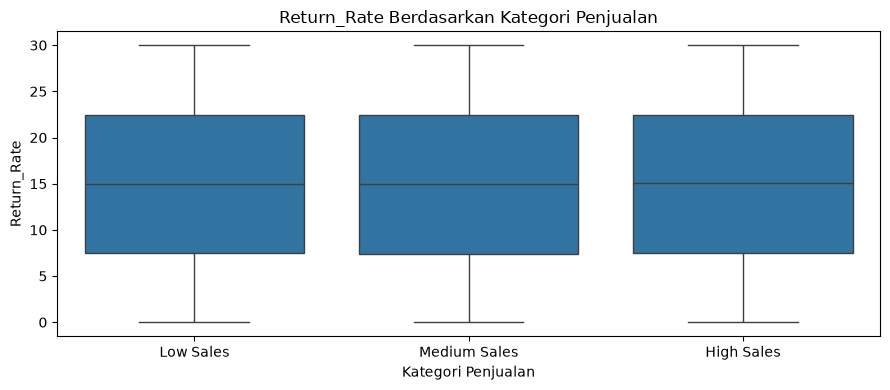

In [9]:

# Perbandingan Fitur Numerik Berdasarkan Target

selected_numeric = [
    "Selling_Price",
    "Cost_Price",
    "Discount_Percentage",
    "Quantity_Sold",
    "Total_Sales",
    "Stock_Availability",
    "Customer_Age",
    "Purchase_Frequency",
    "Store_Rating",
    "Return_Rate"
]

display(
    df.groupby("Sales_Category")[selected_numeric]
      .mean()
      .T
)


# Boxplot Fitur Numerik terhadap Target

for col in selected_numeric:
    plt.figure(figsize=(9, 4))

    sns.boxplot(
        data=df,
        x="Sales_Category",
        y=col,
        order=["Low Sales", "Medium Sales", "High Sales"]
    )

    plt.title(f"{col} Berdasarkan Kategori Penjualan")
    plt.xlabel("Kategori Penjualan")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()



**Temuan 3.7.1 — Fitur numerik terhadap kategori penjualan.**

Rata-rata semua fitur numerik di tiga kelas hampir identik: `Selling_Price` 1.553,89 (High) / 1.546,51 (Low) / 1.561,72 (Medium); `Discount_Percentage` 24,94 / 25,02 / 25,02; `Quantity_Sold` 5,39 / 5,31 / 5,34; `Total_Sales` 50.008 / 50.014 / 50.133; `Customer_Age` 41,11 / 40,92 / 41,17. Selisih antarkelas sangat kecil dibandingkan standar deviasi masing-masing fitur, dan boxplot per kelas menunjukkan persebaran yang saling tumpang tindih. **Indikasi awal: fitur-fitur numerik tidak memisahkan kelas High, Medium, dan Low dengan jelas.** Ini akan diuji lebih lanjut saat pemodelan di Bab 5–6.

### 3.7.2 Hubungan fitur kategorikal dengan kategori penjualan

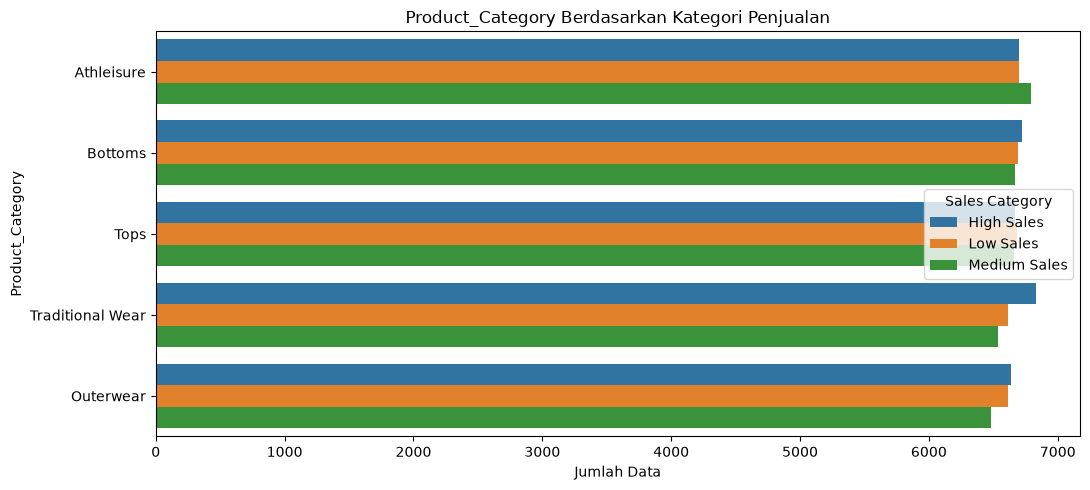

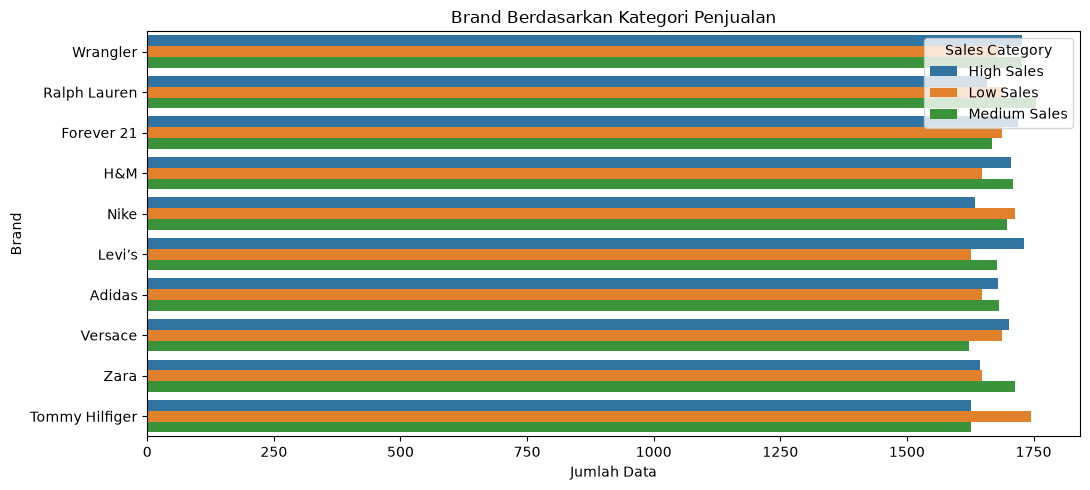

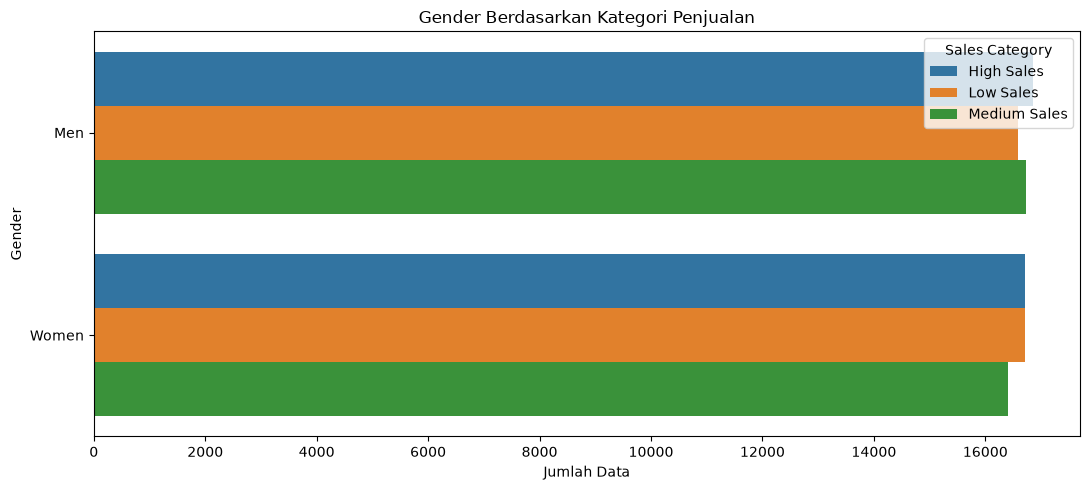

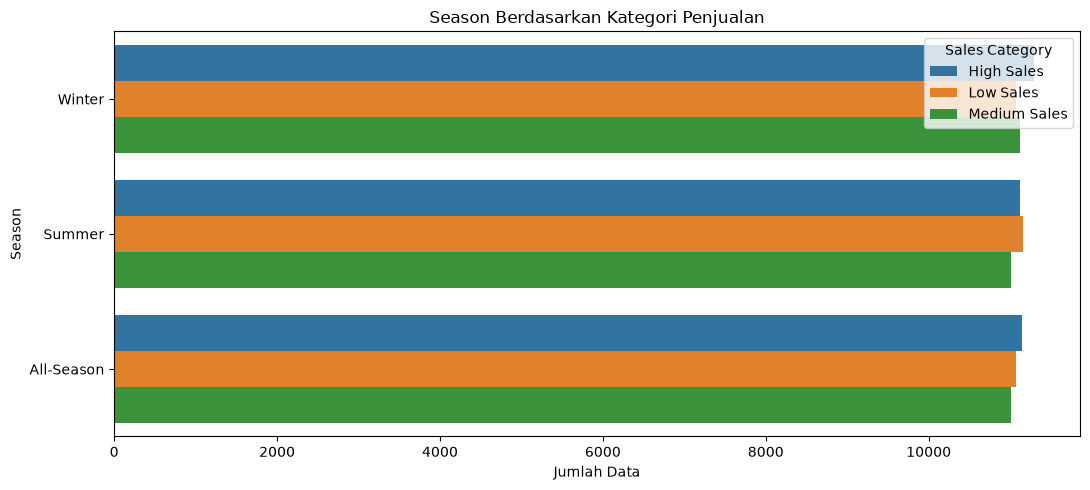

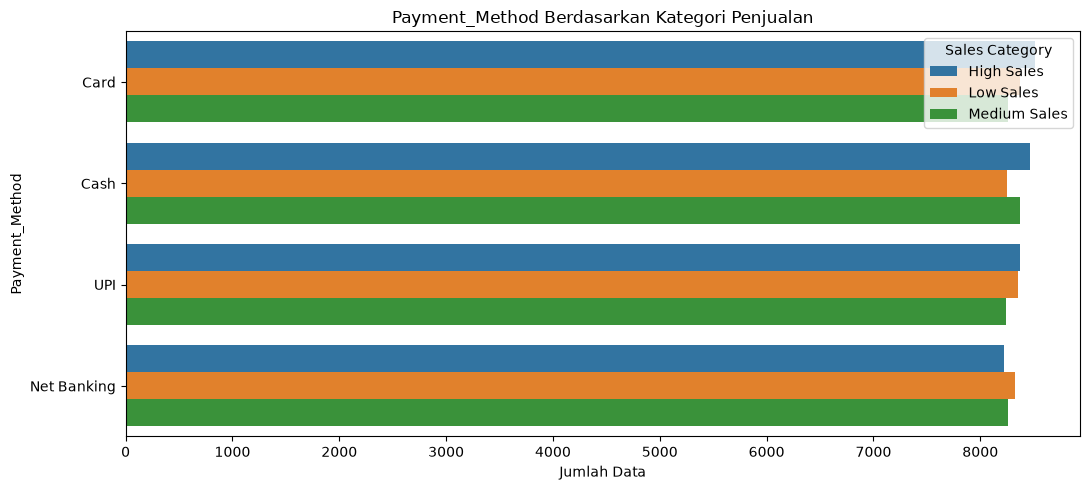

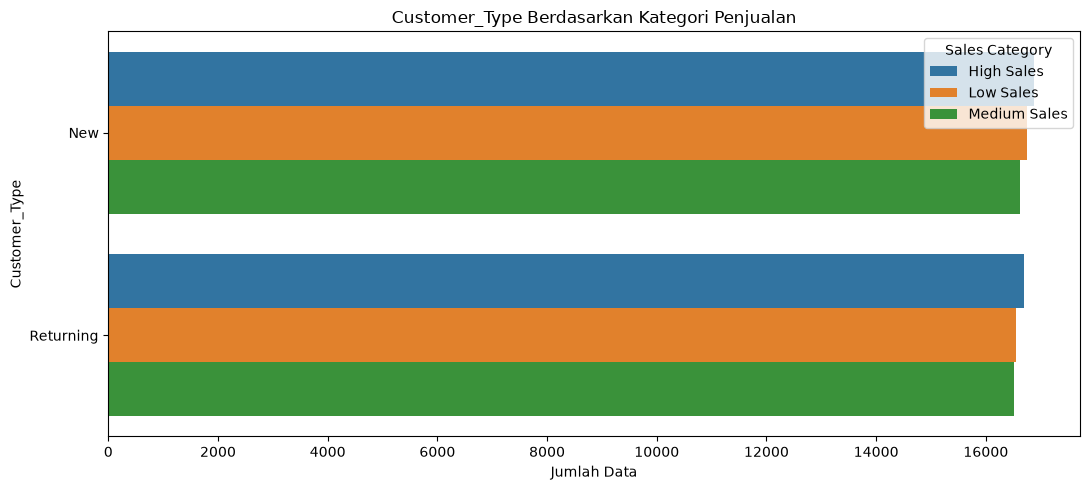

In [10]:

# Hubungan Kategori Produk dengan Target

selected_categorical = [
    "Product_Category",
    "Brand",
    "Gender",
    "Season",
    "Payment_Method",
    "Customer_Type"
]

for col in selected_categorical:
    plt.figure(figsize=(11, 5))

    top_categories = df[col].value_counts().head(10).index
    temp = df[df[col].isin(top_categories)]

    sns.countplot(
        data=temp,
        y=col,
        hue="Sales_Category",
        order=top_categories
    )

    plt.title(f"{col} Berdasarkan Kategori Penjualan")
    plt.xlabel("Jumlah Data")
    plt.ylabel(col)
    plt.legend(title="Sales Category")
    plt.tight_layout()
    plt.show()


**Temuan 3.7.2 — Fitur kategorikal terhadap kategori penjualan.**

Pada setiap kategori, proporsi kelas High Sales relatif sama terhadap proporsi keseluruhan (33,56%). Selisihnya sangat kecil: `Customer_Type` 0,03 poin, `Gender` 0,07 poin, `Season` 0,32 poin, `Payment_Method` 0,70 poin, `Product_Category` 0,99 poin; yang terbesar pun hanya `Brand` dengan 3,25 poin (32,39%–35,64%). Tidak ada kategori produk, merek, musim, atau metode pembayaran yang secara jelas mendominasi salah satu kelas penjualan. Ini memperkuat indikasi dari 3.7.1 bahwa label `Sales_Category` belum menunjukkan hubungan kuat dengan fitur yang tersedia.

## 3.8 Ringkasan Insight Awal

In [11]:

# Ringkasan Statistik Kategori Target

summary_target = df.groupby("Sales_Category").agg(
    Total_Data=("Sales_Category", "count"),
    Rata_Rata_Harga=("Selling_Price", "mean"),
    Rata_Rata_Diskon=("Discount_Percentage", "mean"),
    Rata_Rata_Jumlah_Terjual=("Quantity_Sold", "mean"),
    Rata_Rata_Return=("Return_Rate", "mean")
)

display(summary_target.round(2))


,Total_Data,Rata_Rata_Harga,Rata_Rata_Diskon,Rata_Rata_Jumlah_Terjual,Rata_Rata_Return
Sales_Category,,,,,
High Sales,33561,1553.89,24.94,5.39,15.00
Low Sales,33300,1546.51,25.02,5.31,14.96
Medium Sales,33139,1561.72,25.02,5.34,14.91


## 3.9 Insight Awal berdasarkan EDA

## Insight Awal Berdasarkan EDA

Berdasarkan bagian-bagian sebelumnya, temuan yang benar-benar terlihat dari data adalah:

1. **Target seimbang.** High Sales 33.561, Low Sales 33.300, Medium Sales 33.139 dari 100.000 data; tidak ada ketimpangan kelas yang perlu ditangani.
2. **Fitur numerik memiliki outlier dan nilai negatif.** `Selling_Price`, `Cost_Price`, `Quantity_Sold`, `Total_Sales`, dan `Purchase_Frequency` memiliki ekor panjang; nilai negatif ditemukan pada `Selling_Price` (≈ −613,6), `Cost_Price` (≈ −726,9), `Total_Sales` (≈ −37.155), dan `Purchase_Frequency` (≈ −2,10). Ini menjadi fokus penanganan di Bab 4.
3. **Fitur kategorikal sebarannya merata.** Tidak ada kategori dominan yang ekstrem; `Gender` dan `Customer_Type` hampir 50:50.
4. **Korelasi antarfitur numerik sebagian sedang, bukan kuat.** Pasangan tertinggi `Purchase_Frequency`–`Quantity_Sold` (≈ 0,68), disusul `Selling_Price`–`Cost_Price` (≈ 0,62) dan `Selling_Price`–`Quantity_Sold` (≈ 0,55); tidak ada |r| > 0,8.
5. **Hubungan fitur dengan target sangat lemah.** Rata-rata tiap fitur di kelas High/Medium/Low hampir sama (misalnya `Selling_Price`: High 1.553,89; Medium 1.561,72; Low 1.546,51), dan proporsi High Sales antar kategori kategorikal berbeda kurang dari ≈3,25 poin. **Indikasi awal: label `Sales_Category` tidak terpisah jelas oleh fitur yang tersedia** — akan diverifikasi dengan model di Bab 5 dan dilaporkan apa adanya di Bab 6–7.

# 4. Cleaning dan Preprocessing

Data yang sudah dilihat di Bab 3 masih perlu dibersihkan. Di bab ini dilakukan pengecekan missing value, penghapusan baris yang tidak wajar, pengisian nilai kosong, dan pemilihan fitur. Sesuai readme, kondisi sebelum dan sesudah ditampilkan. Tidak ada fitur buatan yang ditambahkan; yang dipakai hanya kolom yang memang ada di CSV.

## 4.1 Kondisi Data Sebelum Diproses

Langkah pertama adalah melihat kembali jumlah data, missing value, duplikat, dan nilai negatif. Angka-angka ini dipakai sebagai acuan sebelum data diubah.

In [12]:
print("Jumlah baris awal:", df.shape[0])
print("Jumlah kolom awal:", df.shape[1])
missing_awal = df.isnull().sum()
print("\nMissing value per kolom:")
print(missing_awal[missing_awal > 0].to_string())
print("\nTotal missing value:", int(missing_awal.sum()))
print("Duplikat:", int(df.duplicated().sum()))
print("\nNilai negatif:")
print("Selling_Price :", int((df["Selling_Price"] < 0).sum()))
print("Cost_Price    :", int((df["Cost_Price"] < 0).sum()))
print("Total_Sales   :", int((df["Total_Sales"] < 0).sum()))

Jumlah baris awal: 100000
Jumlah kolom awal: 20

Missing value per kolom:
Selling_Price          5000
Discount_Percentage    5000
Stock_Availability     5000
Customer_Age           5000
Store_Rating           5000

Total missing value: 25000
Duplikat: 0

Nilai negatif:
Selling_Price : 133
Cost_Price    : 589
Total_Sales   : 654


## 4.2 Penghapusan Baris dengan Nilai Negatif

Harga jual, harga modal, dan total penjualan tidak mungkin minus, jadi baris seperti itu dibuang. Nilai kosong tidak ikut dibuang karena kasusnya beda; barisnya masih akan diisi di langkah berikutnya.

In [13]:
kolom_invalid = ["Selling_Price", "Cost_Price", "Total_Sales"]
mask = ~(df[kolom_invalid] < 0).any(axis=1)
baris_invalid = int((~mask).sum())
df_clean = df[mask].reset_index(drop=True)

print("Baris negatif dihapus:", baris_invalid)
print("Sebelum:", df.shape, "| Sesudah:", df_clean.shape)
print("Duplikat:", int(df_clean.duplicated().sum()))
n_missing_sebelum = int(df_clean.isnull().sum().sum())
print("Missing sebelum imputasi:", n_missing_sebelum)

Baris negatif dihapus: 1368
Sebelum: (100000, 20) | Sesudah: (98632, 20)
Duplikat: 0
Missing sebelum imputasi: 24667


## 4.3 Imputasi Missing Value

Kolom yang masih punya nilai kosong diisi dengan median. Median dipilih karena `dropna()` akan menghilangkan terlalu banyak baris. Perlu dicatat, median dihitung sebelum data dibagi di Bab 5, jadi data uji ikut memengaruhi angka median sedikit. Ini sengaja dilakukan supaya Bab 4 sudah menampilkan data bersih sesuai readme.

In [14]:
kolom_missing = ["Selling_Price", "Discount_Percentage", "Stock_Availability",
                 "Customer_Age", "Store_Rating"]
nilai_median = df_clean[kolom_missing].median()
print("Median yang dipakai:")
print(nilai_median.round(2).to_string())

df_clean = df_clean.fillna(nilai_median)
n_missing_sesudah = int(df_clean.isnull().sum().sum())
print("\nMissing sebelum:", n_missing_sebelum)
print("Missing sesudah:", n_missing_sesudah)

Median yang dipakai:
Selling_Price          1502.18
Discount_Percentage      25.00
Stock_Availability      251.00
Customer_Age             41.00
Store_Rating              4.00

Missing sebelum: 24667
Missing sesudah: 0


## 4.4 Pemilihan Fitur

Dari 19 prediktor, dua kolom tidak dipakai:

- `Product_Name` dibuang. Di Bab 1.1 yang disebut adalah kategori, merek, ukuran, warna, dan musim; nama produk hanya label dan informasinya sudah ada di `Product_Category` serta `Brand`.
- `Total_Sales` dibuang. Bab 1.1 memakai "jumlah produk yang terjual" (`Quantity_Sold`), bukan total penjualan. Angkanya juga tidak sama dengan `Selling_Price × Quantity_Sold` dan hampir tidak berkorelasi dengan target.

Sisa 17 kolom tetap dipakai. Delapan di antaranya disebut langsung di Bab 1.1, sembilan lainnya masuk informasi pendukung untuk persediaan, promosi, dan evaluasi produk.

In [15]:
fitur_dibuang = ["Product_Name", "Total_Sales"]
df_model = df_clean.drop(columns=fitur_dibuang)
y = df_model["Sales_Category"]
X = df_model.drop(columns="Sales_Category")

print("Prediktor asli:", 19)
print("Dibuang:", fitur_dibuang)
print("Digunakan:", X.shape[1])
print("Daftar fitur yang digunakan:")
for i, f in enumerate(X.columns, 1):
    print(f"{i:2d}. {f}")

Prediktor asli: 19
Dibuang: ['Product_Name', 'Total_Sales']
Digunakan: 17
Daftar fitur yang digunakan:
 1. Product_Category
 2. Brand
 3. Gender
 4. Size
 5. Color
 6. Season
 7. Payment_Method
 8. Customer_Type
 9. Selling_Price
10. Cost_Price
11. Discount_Percentage
12. Quantity_Sold
13. Stock_Availability
14. Customer_Age
15. Purchase_Frequency
16. Store_Rating
17. Return_Rate


## 4.5 Encoding Fitur Kategorikal

Random Forest tidak bisa menerima kolom berisi teks, jadi delapan fitur kategorikal diubah ke angka dengan `LabelEncoder`. Cara ini dipilih supaya jumlah fitur tetap 17. Konsekuensinya, tiap kategori mendapat nomor urut; ini akan disebut sebagai keterbatasan di Bab 7.

In [16]:
from sklearn.preprocessing import LabelEncoder

kolom_kategorikal = X.select_dtypes(include=["object", "category", "str"]).columns.tolist()
print("Fitur kategorikal yang diencode:", kolom_kategorikal)

for col in kolom_kategorikal:
    encoder = LabelEncoder()
    X[col] = encoder.fit_transform(X[col])

print("\nBentuk X setelah encoding:", X.shape)
print("Missing pada X:", int(X.isnull().sum().sum()))

Fitur kategorikal yang diencode: ['Product_Category', 'Brand', 'Gender', 'Size', 'Color', 'Season', 'Payment_Method', 'Customer_Type']

Bentuk X setelah encoding: (98632, 17)
Missing pada X: 0


## 4.6 Ringkasan Bab 4

| Kondisi | Sebelum | Sesudah |
|---|---|---|
| Baris | 100.000 | 98.632 |
| Baris negatif | 1.368 | 0 |
| Nilai kosong | 24.667 sel | 0 |
| Duplikat | 0 | 0 |
| Prediktor | 19 | 17 dipakai, 2 dibuang |

Yang dibuang: `Product_Name` dan `Total_Sales`. Fitur turunan tidak dibuat. Median untuk mengisi nilai kosong dihitung sebelum split, jadi ada pengaruh kecil dari data uji — ini disampaikan di sini supaya jelas.

# 5. Modelling

Setelah data bersih, langkah berikutnya adalah membagi data dan melatih model. Outlier baru ditangani setelah pembagian supaya batasnya dihitung dari data latih saja. Selain Random Forest, model pembanding DummyClassifier juga dicoba untuk melihat apakah model benar-benar belajar.

## 5.1 Membagi Data Latih dan Data Uji

Data dibagi 80% untuk latih dan 20% untuk uji. `stratify=y` dipakai supaya perbandingan tiga kelas tetap sama di kedua bagian, dan `random_state=42` supaya hasilnya bisa diulang.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
n_train0, n_test0 = X_train.shape[0], X_test.shape[0]
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print("Distribusi latih:", y_train.value_counts().to_dict())
print("Distribusi uji  :", y_test.value_counts().to_dict())

Data latih: (78905, 17) | Data uji: (19727, 17)
Distribusi latih: {'High Sales': 26485, 'Low Sales': 26251, 'Medium Sales': 26169}
Distribusi uji  : {'High Sales': 6622, 'Low Sales': 6563, 'Medium Sales': 6542}


## 5.2 Penanganan Outlier dengan IQR

Batas atas dan bawah dihitung dari data latih dengan rumus Q1 − 1,5×IQR dan Q3 + 1,5×IQR. Baris di luar batas dibuang dari latih dan uji. Kolom yang diperiksa hanya empat yang punya ekor panjang: harga jual, harga modal, jumlah terjual, dan frekuensi pembelian.

In [18]:
kolom_outlier = ["Selling_Price", "Cost_Price", "Quantity_Sold", "Purchase_Frequency"]
batas_iqr = {}
print("Batas IQR dari data latih:")
for col in kolom_outlier:
    q1, q3 = X_train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_iqr[col] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)
    print(f"{col:20s}: [{batas_iqr[col][0]:10.2f}, {batas_iqr[col][1]:10.2f}]")

def berisi_outlier(data):
    flag = pd.Series(False, index=data.index)
    for col in kolom_outlier:
        bawah, atas = batas_iqr[col]
        flag |= (data[col] < bawah) | (data[col] > atas)
    return flag

out_latih = berisi_outlier(X_train)
out_uji = berisi_outlier(X_test)
n_out = int(out_latih.sum() + out_uji.sum())
print("\nOutlier dibuang - latih:", int(out_latih.sum()), "| uji:", int(out_uji.sum()))
X_train, y_train = X_train[~out_latih], y_train[~out_latih]
X_test, y_test = X_test[~out_uji], y_test[~out_uji]
n_train1, n_test1 = X_train.shape[0], X_test.shape[0]
print("Sesudah outlier - latih:", X_train.shape, "| uji:", X_test.shape)

Batas IQR dari data latih:
Selling_Price       : [    230.43,    2771.99]
Cost_Price          : [    -73.08,    2089.62]
Quantity_Sold       : [     -3.00,      13.00]
Purchase_Frequency  : [     -0.71,       4.72]

Outlier dibuang - latih: 1899 | uji: 483
Sesudah outlier - latih: (77006, 17) | uji: (19244, 17)


## 5.3 Melatih Random Forest

Model memakai 100 pohon dengan kedalaman maksimal 5 dan criterion gini. Nilai `random_state=42` dipakai lagi supaya hasilnya konsisten. Random Forest tidak butuh scaling, jadi langkah itu dilewat.

In [19]:
model_rf = RandomForestClassifier(
    n_estimators=100, max_depth=5, criterion="gini", random_state=42
)
model_rf.fit(X_train, y_train)
print("Model berhasil dilatih")
print("Jumlah pohon:", len(model_rf.estimators_))
print("Jumlah fitur:", X_train.shape[1])

Model berhasil dilatih
Jumlah pohon: 100
Jumlah fitur: 17


## 5.4 Model Pembanding

DummyClassifier dengan strategi `most_frequent` hanya menebak kelas yang paling sering muncul. Model ini sengaja dilatih untuk mengecek apakah Random Forest benar-benar lebih baik dari sekadar menebak.

In [20]:
model_dummy = DummyClassifier(strategy="most_frequent")
model_dummy.fit(X_train, y_train)
print("Kelas mayoritas:", y_train.value_counts().idxmax())

Kelas mayoritas: High Sales


# 6. Evaluasi

Penilaian memakai macro F1 sebagai metrik utama, seperti yang sudah ditetapkan di Bab 1.5. Accuracy, precision, recall, confusion matrix, dan feature importance dipakai sebagai pendukung.

## 6.1 Prediksi dan Metrik

Data uji diprediksi dengan kedua model. Hasilnya dibandingkan supaya terlihat apakah Random Forest memberi keuntungan dibanding tebakan mayoritas.

In [21]:
from sklearn.metrics import f1_score
y_pred = model_rf.predict(X_test)
y_pred_dummy = model_dummy.predict(X_test)

acc_rf = accuracy_score(y_test, y_pred)
f1_rf = f1_score(y_test, y_pred, average="macro")
acc_dummy = accuracy_score(y_test, y_pred_dummy)
f1_dummy = f1_score(y_test, y_pred_dummy, average="macro")

print("Random Forest - accuracy :", round(acc_rf, 4))
print("Random Forest - macro F1 :", round(f1_rf, 4))
print("Dummy        - accuracy :", round(acc_dummy, 4))
print("Dummy        - macro F1 :", round(f1_dummy, 4))
print("\nClassification Report (Random Forest):")
print(classification_report(y_test, y_pred, labels=sorted(y.unique())))

Random Forest - accuracy : 0.3389
Random Forest - macro F1 : 0.3145
Dummy        - accuracy : 0.3354
Dummy        - macro F1 : 0.1674

Classification Report (Random Forest):
              precision    recall  f1-score   support

  High Sales       0.34      0.59      0.43      6454
   Low Sales       0.34      0.28      0.31      6408
Medium Sales       0.34      0.15      0.21      6382

    accuracy                           0.34     19244
   macro avg       0.34      0.34      0.31     19244
weighted avg       0.34      0.34      0.31     19244



## 6.2 Confusion Matrix

Matriks ini menunjukkan berapa data yang benar dan berapa yang salah masuk kelas lain untuk setiap kategori.

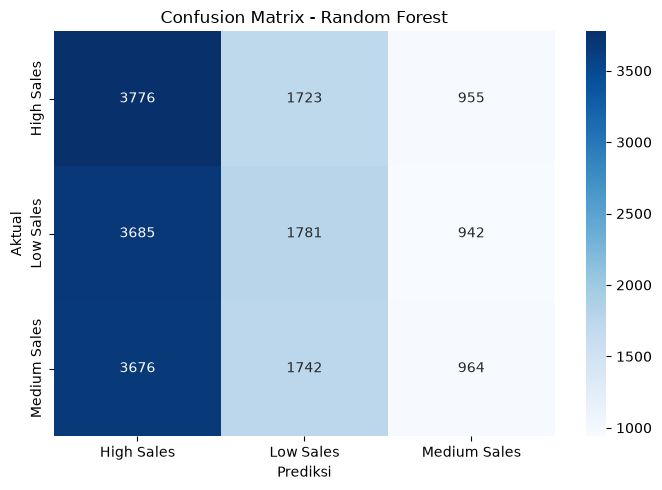

In [22]:
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

## 6.3 Feature Importance

Bagian ini menjawab pertanyaan keempat di Bab 1.2, yaitu fitur mana yang paling berpengaruh menurut model.

              Fitur  Importance
        Return_Rate      0.1165
         Cost_Price      0.1159
 Purchase_Frequency      0.1129
      Selling_Price      0.1100
       Store_Rating      0.1084
Discount_Percentage      0.1083
 Stock_Availability      0.0783
       Customer_Age      0.0537
              Brand      0.0476
      Quantity_Sold      0.0370
              Color      0.0233
               Size      0.0216
   Product_Category      0.0183
     Payment_Method      0.0164
             Gender      0.0135
             Season      0.0115
      Customer_Type      0.0068

Jumlah importance: 1.0


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_2084\444105302.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Importance", y="Fitur", data=fi, palette="viridis")


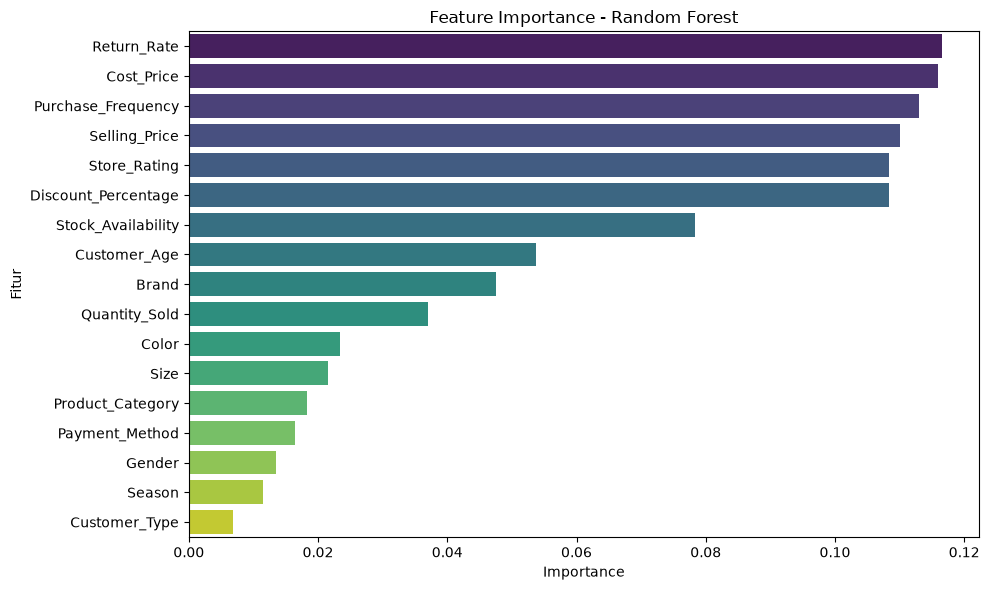

In [23]:
importances = model_rf.feature_importances_
fi = pd.DataFrame({
    "Fitur": X_train.columns,
    "Importance": importances
}).sort_values("Importance", ascending=False)

print(fi.round(4).to_string(index=False))
print("\nJumlah importance:", round(importances.sum(), 4))

plt.figure(figsize=(10, 6))
sns.barplot(x="Importance", y="Fitur", data=fi, palette="viridis")
plt.title("Feature Importance - Random Forest")
plt.tight_layout()
plt.show()

## 6.4 Interpretasi Hasil

Random Forest mendapat accuracy 0,3389 dan macro F1 0,3145. DummyClassifier mendapat 0,3354 dan 0,1674. Jadi selisih accuracy hanya 0,0035.

Angka itu berarti dari 100 produk, sekitar 34 diprediksi tepat. Tebakan mayoritas saja sudah mendapat sekitar 33,5 produk tepat. Saat dilihat per kelas, recall High Sales 0,59 tetapi Medium Sales hanya 0,15, jadi model lebih sering memilih High Sales.

Tiga importance terbesar adalah `Return_Rate`, `Cost_Price`, dan `Purchase_Frequency`. Nilainya tidak jauh berbeda satu sama lain dan korelasi fitur dengan target di Bab 3 juga hampir nol, jadi ini tidak bisa diartikan sebagai bukti bahwa ketiga fitur itu menentukan penjualan. Hasilnya dilaporkan apa adanya.

# 7. Konklusi

Menjawab pertanyaan di Bab 1.2:

1. Dataset berisi 100.000 baris dengan tiga kelas yang jumlahnya hampir sama (High 33.561, Low 33.300, Medium 33.139). Dari EDA, rata-rata fitur di ketiga kelas hampir sama dan korelasi fitur dengan target mendekati nol. Jadi karakteristik yang tersedia belum menunjukkan hubungan yang jelas dengan performa penjualan.

2. Random Forest dilatih dengan 17 fitur asli. Dua kolom, `Product_Name` dan `Total_Sales`, tidak dipakai dengan alasan yang sudah dijelaskan di Bab 4.4. Model memakai 100 pohon, `max_depth=5`, dan gini.

3. Hasilnya accuracy 0,3389 dan macro F1 0,3145. Baseline DummyClassifier mendapat 0,3354 dan 0,1674. Dengan kata lain, dari 100 produk hanya sekitar 34 yang tepat, hampir sama dengan menebak kelas mayoritas (sekitar 33,5).

4. Tiga fitur dengan importance tertinggi adalah `Return_Rate`, `Cost_Price`, dan `Purchase_Frequency`. Ini hanya urutan dari model, bukan bukti hubungan sebab-akibat.

Keputusan yang diambil: hasil klasifikasi belum mendukung pengambilan keputusan bisnis retail. Data perlu dilengkapi dengan label performa yang benar-benar berkaitan dengan fitur produk.

Keterbatasan: median dihitung sebelum split, `LabelEncoder` memberi urutan buatan pada kategori, outlier dibuang dengan aturan IQR, dan dataset sumber memang mengandung anomali.